# Neural Network (MLP) — working file for Section 3 of `main.ipynb`

Neural network only. Built on the shared harness from `work_Guangyu.ipynb` (same `a2_common`, `SPLITS`, three feature sets, `run_experiment()` loop, metrics and baseline), so every MLP number is directly comparable with the classical models. Comparison tables across models belong to 2.5 / Section 4, not here.

**中文导读（合并进 `main.ipynb` 时删掉这一格）**

| 节 | 做什么 | 进报告哪里 |
|---|---|---|
| 3.0 | 共用设置：和 Guangyu 的 2.0 完全一样（合并时直接用 §1.5 的共用代码，这里的副本删掉） | — |
| 3.1 | 用 `run_experiment()` 训练 + 调参：4 个时间点 × 3 套特征 | Method：调参 |
| 3.2 | 结果表 + 相对 baseline 的提升 | Results：RQ1 / RQ2 |
| 3.3 | 调参曲线 + 每格选中的值 | Method：解释选中的值 |
| 3.4 | 错误分析素材：混淆矩阵、按结果 / 模块 / 个案 | Discussion：错误分析 |
| 3.5 | （可选，MLP only）随机种子敏感性 | Discussion：局限 |
| 3.6 | 交付：`mlp_rows`、`mlp_curve`、`mlp_pipe` + csv | 给 2.5 / Section 4 |

**规则（和 Guangyu 的一样）：** 只用 `a2_common` 做划分、预处理、指标；只在验证集上调参；在 train+val 上重训；每格测试集只评估一次；每个模型都传 `SEED`；不开 log 变换；时间点之间不合并。

**环境：** scikit-learn 1.9.1、pandas 3.0.6。每节末尾的 ✅ 是我在这个环境里跑出的数字，用来自检。

## 3.0 Setup *(identical to Guangyu's 2.0 — in `main.ipynb` this comes from the shared harness §1.5)*

In [1]:
# import tool libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
import sklearn

# import sklearn models
from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.neural_network import MLPClassifier  # Model 4
from sklearn.metrics import confusion_matrix

# import helper for processing data
import a2_common as A2

# set global variables
SEED = A2.SEED
CUTOFF_DAYS = A2.CUTOFF_DAYS  # [0, 24, 60, 120]
print("scikit-learn", sklearn.__version__, "| pandas", pd.__version__)

scikit-learn 1.9.1 | pandas 3.0.5


In [2]:
# one train/val/test split per cutoff (RQ1), grouped by student
SPLITS = {cut: A2.make_splits(A2.load_table(cut)) for cut in CUTOFF_DAYS}

# define feature groups: background, behaviour, all for RQ2
FEATURE_SETS = {
    "background": A2.feature_cols("baseline"),
    "behaviour": A2.feature_cols("behaviour"),
    "all": A2.feature_cols("engineered")
}
print({k: len(v) for k, v in FEATURE_SETS.items()}, "| day-24 split sizes:", [len(x) for x in SPLITS[24]])

{'background': 14, 'behaviour': 38, 'all': 52} | day-24 split sizes: [16688, 5563, 5562]


✅ `{'background': 14, 'behaviour': 38, 'all': 52}`，第 24 天 `[16688, 5563, 5562]`。

In [3]:
# run experiment for a given model, parameter (and values), cutoffs, and feature sets
# (copied from work_Guangyu.ipynb without changes)
def run_experiment(name, model, param, values, cutoffs=CUTOFF_DAYS, feature_sets=None):
    rows, curve, best_pipe = [], {}, None
    # using cutoffs to answer RQ1
    for cut in cutoffs:
        train, val, test = SPLITS[cut]
        train_val = pd.concat([train, val], ignore_index=True)
        for fs, cols in (feature_sets or FEATURE_SETS).items():
            # using feature sets to answer RQ2
            val_f1 = {}
            for v in values:
                # set model parameters
                m = clone(model).set_params(**{param: v})
                # fit on train, macro-F1 on val
                val_f1[v] = A2.score_model(m, cols, train, val)[1]["macro_f1"]
            best = max(val_f1, key=val_f1.get)

            # refit best on train+val, score test once
            m = clone(model).set_params(**{param: best})
            pipe, scores = A2.score_model(m, cols, train_val, test)
            rows.append({"model": name, "cutoff": cut, "feature_set": fs,
                         "best_param": f"{param}={best}", **scores})
            if cut == 24 and fs == "all":
                curve = val_f1
                best_pipe = pipe
    return rows, curve, best_pipe


# plot the tuning curve for a given model (copied from work_Guangyu.ipynb)
def plot_curve(name, curve, param):
    xaxis = [str(v) for v in curve]
    best = max(curve, key=curve.get)
    plt.figure(figsize=(6, 4))
    plt.plot(xaxis, list(curve.values()), marker='o')
    plt.axvline(list(curve).index(best), linestyle='--', color='grey',
                label=f"chosen {param} = {best}")
    plt.title(f"{name} tuning curve (cutoff 24, all features)")
    plt.xlabel(param)
    plt.ylabel("Validation macro-F1")
    plt.xticks(rotation=45)
    plt.legend()
    plt.grid()
    plt.show()

In [4]:
# majority-class baseline, same call as Guangyu's 2.1 (needed here for the lift column)
base_rows, _, _ = run_experiment("Baseline", DummyClassifier(random_state=SEED),
                                 "strategy", ["most_frequent"],
                                 feature_sets={"—": FEATURE_SETS["background"]})
BASELINE = {r["cutoff"]: r["macro_f1"] for r in base_rows}
BASELINE

{0: 0.3428, 24: 0.3562, 60: 0.3685, 120: 0.3831}

✅ `{0: 0.3428, 24: 0.3562, 60: 0.3685, 120: 0.3831}` —— 和 Guangyu 的 2.1 完全一样。

## 3.1 Train & tune

Flexible model: low bias, variance controlled by `alpha` (L2) and early stopping. Tune `hidden_layer_sizes`.

Multilayer perceptron: one or two hidden layers of ReLU units, Adam optimiser, L2 penalty `alpha`, early stopping on 10 % of the training rows. Like the other three models, **one hyperparameter is tuned**: `hidden_layer_sizes`, i.e. network capacity. `alpha` is fixed at 0.001.

**为什么调 `hidden_layer_sizes`（写进 Method）：**
- 和 DT 的 `max_depth` 一样是在调**容量**：太小欠拟合（高 bias），太大过拟合（高 variance），调参曲线可以直接用 bias–variance 解释（第 11 讲）。
- 我也试过只调 `alpha`：验证集曲线只差 0.003，选出的值在各格子间乱跳，不好解释；调容量差 0.007。
- 候选值**从小到大**排：打平时 `max()` 取第一个，也就是更小的网络，和其他模型"打平选简单"的规则一致。
- `random_state=SEED` 必须传：MLP 的初始权重是随机的（第 15 讲），不传就无法复现。
- 不开 log 变换：传统模型都没开，MLP 也不开，保持一致。

**自己写的思路：** 构造一个 `MLPClassifier`（固定的参数都放进去），然后像 Guangyu 调 LR 那样调用 `run_experiment(名字, 模型, 参数名, 候选值列表)`。

In [5]:
# run experiment for the MLP
# tune hidden_layer_sizes (network capacity) on the validation set;
# alpha (L2 strength) is fixed; early stopping holds out 10% of the training rows
mlp_rows, mlp_curve, mlp_pipe = run_experiment(
    "MLP",
    MLPClassifier(alpha=1e-3, early_stopping=True, max_iter=400, random_state=SEED),
    "hidden_layer_sizes", [(16,), (32,), (64,), (128,), (64, 32)])

✅ 约 1–2 分钟。

## 3.2 Results

Test macro-F1 by feature set × cutoff, and the lift over **that cutoff's own** majority baseline (the class balance changes across cutoffs, so raw scores are not comparable).

In [6]:
mlp_df = pd.DataFrame(mlp_rows)
mlp_table = mlp_df.pivot(index="cutoff", columns="feature_set", values="macro_f1")[["background", "behaviour", "all"]]
mlp_table["baseline"] = pd.Series(BASELINE)
mlp_table["lift (all)"] = mlp_table["all"] - mlp_table["baseline"]
mlp_table["gain from behaviour (all - background)"] = mlp_table["all"] - mlp_table["background"]
display(mlp_table.round(4))

# ROC-AUC and at-risk recall for the same cells (used in the Discussion of RQ2):
# AUC does not depend on the 0.5 threshold, recall does
for metric in ["roc_auc", "recall"]:
    print(metric)
    display(mlp_df.pivot(index="cutoff", columns="feature_set", values=metric)[["background", "behaviour", "all"]].round(4))

# sanity check (same as Guangyu's): ROC-AUC > 0.95 would suggest leakage
assert mlp_df.roc_auc.max() < 0.95, "suspect leakage"
print("max ROC-AUC:", mlp_df.roc_auc.max())

feature_set,background,behaviour,all,baseline,lift (all),gain from behaviour (all - background)
cutoff,,,,,,
0,0.6091,0.6221,0.6573,0.3428,0.3145,0.0482
24,0.6019,0.6784,0.7062,0.3562,0.3500,0.1043
60,0.5950,0.7484,0.7612,0.3685,0.3927,0.1662
120,0.5832,0.7931,0.7986,0.3831,0.4155,0.2154


roc_auc


feature_set,background,behaviour,all
cutoff,,,
0,0.6543,0.6653,0.7196
24,0.6488,0.7481,0.7722
60,0.6648,0.8269,0.8437
120,0.6569,0.8753,0.8799


recall


feature_set,background,behaviour,all
cutoff,,,
0,0.5454,0.6269,0.5932
24,0.4833,0.5304,0.6121
60,0.3986,0.6342,0.6433
120,0.3056,0.6805,0.6837


max ROC-AUC: 0.8799


✅

| cutoff | background | behaviour | all | baseline | lift (all) | gain |
|---|---|---|---|---|---|---|
| 0 | 0.6091 | 0.6221 | 0.6573 | 0.3428 | 0.3145 | 0.0482 |
| 24 | 0.6019 | 0.6784 | 0.7062 | 0.3562 | 0.3500 | 0.1043 |
| 60 | 0.5950 | 0.7484 | 0.7612 | 0.3685 | 0.3927 | 0.1662 |
| 120 | 0.5832 | 0.7931 | 0.7986 | 0.3831 | 0.4155 | 0.2154 |

ROC-AUC：background 0.6543 / 0.6488 / 0.6648 / 0.6569（基本持平），all 0.7196 / 0.7722 / 0.8437 / 0.8799（第 0 / 24 / 60 / 120 天）。background 的 recall：0.5454 / 0.4833 / 0.3986 / 0.3056（大幅下降）。正文 Discussion 里"AUC 持平、recall 下降"的数字就来自这两张表。

**怎么读（RQ1 / RQ2）：** all 在第 0 天就比 baseline 高 0.31，之后一路上升；background 不升反降；behaviour 单独用到第 120 天几乎追上 all（0.793 vs 0.799）。

## 3.3 Tuning curve

Validation macro-F1 against `hidden_layer_sizes` at cutoff 24, all features — explains the chosen value. Then the value chosen in every cell.

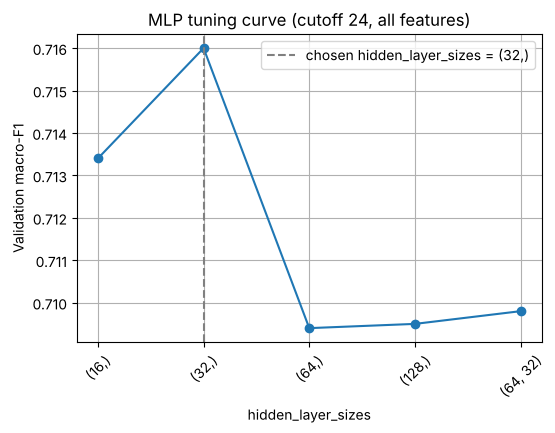

{'(16,)': 0.7134, '(32,)': 0.716, '(64,)': 0.7094, '(128,)': 0.7095, '(64, 32)': 0.7098}
range of the curve: 0.0066


feature_set,all,background,behaviour
cutoff,,,
0,"hidden_layer_sizes=(64,)","hidden_layer_sizes=(128,)","hidden_layer_sizes=(64,)"
24,"hidden_layer_sizes=(32,)","hidden_layer_sizes=(128,)","hidden_layer_sizes=(128,)"
60,"hidden_layer_sizes=(64,)","hidden_layer_sizes=(16,)","hidden_layer_sizes=(128,)"
120,"hidden_layer_sizes=(128,)","hidden_layer_sizes=(64,)","hidden_layer_sizes=(64,)"


In [7]:
plot_curve("MLP", mlp_curve, "hidden_layer_sizes")
print({str(k): v for k, v in mlp_curve.items()})
print(f"range of the curve: {max(mlp_curve.values()) - min(mlp_curve.values()):.4f}")

# the chosen hidden_layer_sizes for each cell in FEATURE_SETS x CUTOFF_DAYS
mlp_df.pivot(index="cutoff", columns="feature_set", values="best_param")

✅ 曲线：(16) 0.7134、(32) **0.7160**、(64) 0.7094、(128) 0.7095、(64, 32) 0.7098；范围 0.0066。

**怎么写进报告：** 5 种结构只差 0.007，说明容量不是瓶颈；最小的两个网络反而最好，更大的网络没有带来收益。各格子选中的结构不同，但都在这个很窄的范围内，所以"选哪个"对结论影响很小。

## 3.4 Error analysis material *(MLP at cutoff 24, all features)*

The chosen pipeline's predictions on the test set: confusion matrix, share correct by true outcome, recall by withdrawal timing and by module, and the most confident errors. `date_unregistration` is used **only to analyse**, never as a feature.

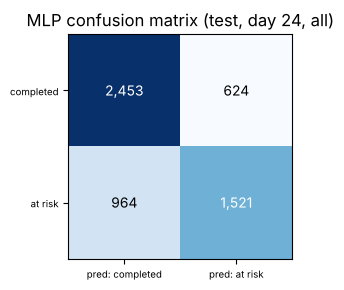

TN=2,453 FP=624 FN=964 TP=1,521


In [8]:
train, val, test = SPLITS[24]
cols = FEATURE_SETS["all"]
proba = mlp_pipe.predict_proba(test[cols])[:, 1]
pred = (proba >= 0.5).astype(int)
y = test[A2.TARGET].values

cm = confusion_matrix(y, pred)
plt.figure(figsize=(3.4, 3))
plt.imshow(cm, cmap="Blues")
for i in range(2):
    for j in range(2):
        plt.text(j, i, f"{cm[i, j]:,}", ha="center", va="center",
                 color="white" if cm[i, j] > cm.max() * .55 else "black")
plt.xticks([0, 1], ["pred: completed", "pred: at risk"], fontsize=7)
plt.yticks([0, 1], ["completed", "at risk"], fontsize=7)
plt.title("MLP confusion matrix (test, day 24, all)")
plt.tight_layout(); plt.show()
tn, fp, fn, tp = cm.ravel()
print(f"TN={tn:,} FP={fp:,} FN={fn:,} TP={tp:,}")

In [9]:
ea = test[["final_result", "code_module", "date_unregistration", "vle_total_clicks", "vle_active_days",
           "asm_n_submitted", "asm_mean_score", "has_asm_activity", A2.TARGET]].copy()
ea["proba"], ea["pred"] = proba, pred
ea["correct"] = ea.pred == ea[A2.TARGET]

print("1) share correct by true outcome")
display(ea.groupby("final_result").correct.agg(["mean", "size"]).round(3))

w = ea[ea.final_result == "Withdrawn"].copy()
w["withdraw_day"] = pd.cut(w.date_unregistration, [24, 60, 120, 180, 1000], labels=["25-60", "61-120", "121-180", ">180"])
print("2) recall on withdrawn students by withdrawal day")
display(w.groupby("withdraw_day", observed=False).pred.agg(["mean", "size"]).round(3))

print("3) by module")
display(ea.groupby("code_module").apply(lambda g: pd.Series(dict(
    n_at_risk=int(g[A2.TARGET].sum()),
    recall=g.loc[g[A2.TARGET] == 1, "pred"].mean(),
    fp_rate=g.loc[g[A2.TARGET] == 0, "pred"].mean(),
    no_submission_pct=(g.has_asm_activity == 0).mean() * 100))).round(3))

show = ["final_result", "code_module", "date_unregistration", "vle_total_clicks", "vle_active_days",
        "asm_n_submitted", "asm_mean_score", "proba"]
print("4a) most confident false negatives")
display(ea[(ea[A2.TARGET] == 1) & (ea.pred == 0)].sort_values("proba").head(5)[show].round(3))
print("4b) most confident false positives")
display(ea[(ea[A2.TARGET] == 0) & (ea.pred == 1)].sort_values("proba", ascending=False).head(5)[show].round(3))
print("5) median clicks: missed at-risk %.0f | caught at-risk %.0f | completers %.0f" % (
    ea[(ea[A2.TARGET] == 1) & (ea.pred == 0)].vle_total_clicks.median(),
    ea[(ea[A2.TARGET] == 1) & (ea.pred == 1)].vle_total_clicks.median(),
    ea[ea[A2.TARGET] == 0].vle_total_clicks.median()))

1) share correct by true outcome


,mean,size
final_result,,
Distinction,0.926,598
Fail,0.605,1406
Pass,0.766,2479
Withdrawn,0.621,1079


2) recall on withdrawn students by withdrawal day


,mean,size
withdraw_day,,
25-60,0.759,311
61-120,0.599,314
121-180,0.521,280
>180,0.536,151


3) by module


,n_at_risk,recall,fp_rate,no_submission_pct
code_module,,,,
AAA,29.0,0.207,0.072,11.429
BBB,551.0,0.566,0.153,13.297
CCC,359.0,0.730,0.299,11.293
DDD,532.0,0.739,0.306,35.939
EEE,191.0,0.424,0.140,95.984
FFF,635.0,0.616,0.199,13.150
GGG,188.0,0.404,0.173,98.453


4a) most confident false negatives


,final_result,code_module,date_unregistration,vle_total_clicks,vle_active_days,asm_n_submitted,asm_mean_score,proba
5314,Fail,GGG,NaN,794.0,29.0,1.0,82.0,0.032
1932,Withdrawn,CCC,132.0,2909.0,43.0,2.0,90.5,0.038
2535,Withdrawn,DDD,177.0,1296.0,26.0,1.0,85.0,0.039
3972,Withdrawn,FFF,149.0,1133.0,33.0,1.0,88.0,0.041
4653,Withdrawn,FFF,115.0,1094.0,23.0,1.0,94.0,0.041


4b) most confident false positives


,final_result,code_module,date_unregistration,vle_total_clicks,vle_active_days,asm_n_submitted,asm_mean_score,proba
2088,Pass,CCC,NaN,0.0,0.0,0.0,NaN,1.000
4377,Pass,FFF,NaN,23.0,7.0,0.0,NaN,0.997
3776,Pass,FFF,NaN,0.0,0.0,0.0,NaN,0.980
454,Pass,BBB,NaN,0.0,0.0,0.0,NaN,0.979
4566,Pass,FFF,NaN,90.0,3.0,0.0,NaN,0.975


5) median clicks: missed at-risk 250 | caught at-risk 95 | completers 271


✅ TN 2,453、FP 624、FN 964、TP 1,521。判对比例：Distinction 0.926、Pass 0.766、Fail 0.605、Withdrawn 0.621。退课学生 recall：25–60 天 0.759 → 121–180 天 0.521。模块 recall：GGG 0.404、EEE 0.424（96–98% 的学生第 24 天还没交作业），AAA 0.207（只有 29 个有风险学生，不稳定）。漏报学生点击数中位数 250，接近完成课程的学生（271），远高于抓到的有风险学生（95）。最有把握的误报：点击 0、没交作业、却完成了课程的学生（概率约 1.0）。

**分析每个错误时问三个问题：** 第 24 天这个学生看起来像哪一类？是数据的局限（还没有信号）还是模型的局限（有信号没学到）？怎样改进（更晚的时间点、按模块的作业日期设时间点）？

## 3.5 *(Optional, MLP only)* Seed sensitivity

The MLP's initial weights are random. Re-fit the chosen setting at cutoff 24 / all with five seeds (fit on **train**, score on **validation**) to see how much the score moves. The test set is not touched again, so the rule "test scored once per cell" still holds. **Not part of the shared protocol** — report it only as a limitation, and say it was done for the MLP only.

In [10]:
best_h = eval(mlp_df[(mlp_df.cutoff == 24) & (mlp_df.feature_set == "all")].best_param.iloc[0].split("=")[1])
seed_f1 = [A2.score_model(MLPClassifier(hidden_layer_sizes=best_h, alpha=1e-3, early_stopping=True,
                                        max_iter=400, random_state=s), cols, train, val)[1]["macro_f1"]
           for s in range(5)]
print("hidden_layer_sizes =", best_h, "| validation macro-F1 over 5 seeds:", seed_f1)
print(f"mean {np.mean(seed_f1):.4f}, SD {np.std(seed_f1, ddof=1):.4f}, range {max(seed_f1) - min(seed_f1):.4f}")

hidden_layer_sizes = (32,) | validation macro-F1 over 5 seeds: [0.713, 0.7134, 0.7097, 0.708, 0.7051]
mean 0.7098, SD 0.0035, range 0.0083


✅ 5 个种子（验证集）：0.7130、0.7134、0.7097、0.7080、0.7051；均值 0.7098，标准差 0.0035，范围 0.0083。**换种子带来的波动（0.008）比 MLP 和 LR 的差距大**：测试集差 0.001（0.7062 vs 0.7072），验证集差 0.0055（0.716 vs 0.7105）。这是 Discussion 里“MLP 没有比 LR 更好”的关键证据。测试集没有被再次使用。

## 3.6 Delivery

Same three outputs as each classical model. The MLP has the highest validation macro-F1 at cutoff 24 / all (0.716), so Guangyu's 2.5.2 rule will pick `mlp_pipe` for the error analysis in Section 4. In `main.ipynb`:
- 2.5.1: `results = pd.DataFrame(base_rows + log_rows + dt_rows + rf_rows + mlp_rows)` and `assert len(results) == 52`
- 2.5.2: add `"MLP": max(mlp_curve.values())` to `val_best` and `"MLP": mlp_pipe` to `best_model`

In [11]:
assert len(mlp_rows) == 12
mlp_df.to_csv(Path("processed") / "results_MLP.csv", index=False)
print("saved processed/results_MLP.csv | validation best (cutoff 24, all):", max(mlp_curve.values()))

saved processed/results_MLP.csv | validation best (cutoff 24, all): 0.716
